# Lab 9 Morphological Operations


Balls.png: 1274 x 1234, Otsu threshold 127
Erosion2.jpg: 947 x 807, Otsu threshold 129
BoundaryExtraction.jpg: 436 x 533, Otsu threshold 128
Open_Closing.jpg: 460 x 307, Otsu threshold 114
Opening2.jpg: 716 x 402, Otsu threshold 126


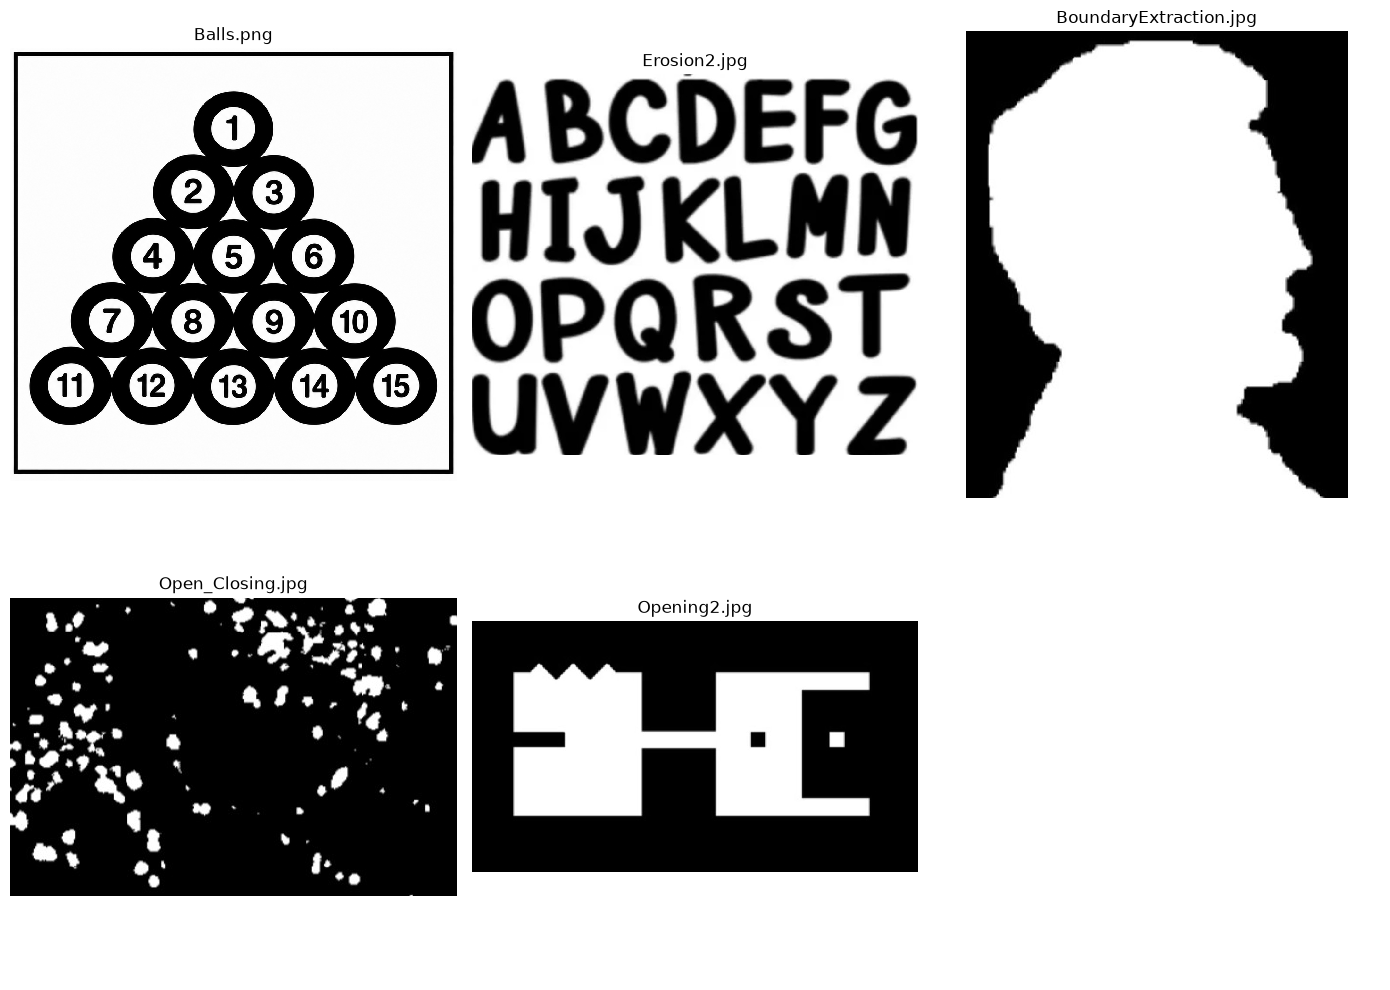

In [ ]:
from pathlib import Path
import json
import base64
import hashlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

names = ['Balls.png', 'Erosion2.jpg', 'BoundaryExtraction.jpg', 'Open_Closing.jpg', 'Opening2.jpg']
folders = [Path.cwd(), Path.cwd() / 'outputs', Path.cwd().parent / 'outputs', Path.home() / 'Downloads']
store = None
for folder in folders:
    for path in sorted(folder.glob('*.ipynb')):
        try:
            saved = json.loads(path.read_text(encoding='utf-8')).get('metadata', {}).get('lab9_morph_assets', {})
        except (OSError, UnicodeError, json.JSONDecodeError):
            continue
        if all(name in saved for name in names):
            store = saved
            break
    if store is not None:
        break
if store is None:
    raise FileNotFoundError('Save this notebook in the Jupyter working directory and run all cells again.')
images = {}
binary_images = {}
for name in names:
    raw = base64.b64decode(store[name]['base64'], validate=True)
    assert hashlib.sha256(raw).hexdigest() == store[name]['sha256']
    image = cv2.imdecode(np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    assert image is not None
    images[name] = image
    polarity = cv2.THRESH_BINARY_INV if name in ['Balls.png', 'Erosion2.jpg'] else cv2.THRESH_BINARY
    threshold, binary_images[name] = cv2.threshold(image, 0, 255, polarity + cv2.THRESH_OTSU)
    print(f'{name}: {image.shape[1]} x {image.shape[0]}, Otsu threshold {threshold:.0f}')

def show(items, columns=3, size=(14, 9)):
    rows = (len(items) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=size, squeeze=False)
    for ax, (title, image) in zip(axes.flat, items):
        ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        ax.set_title(title)
        ax.axis('off')
    for ax in axes.flat[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

show(list(images.items()), size=(14, 10))

## Task 1 Apply four operations to Balls



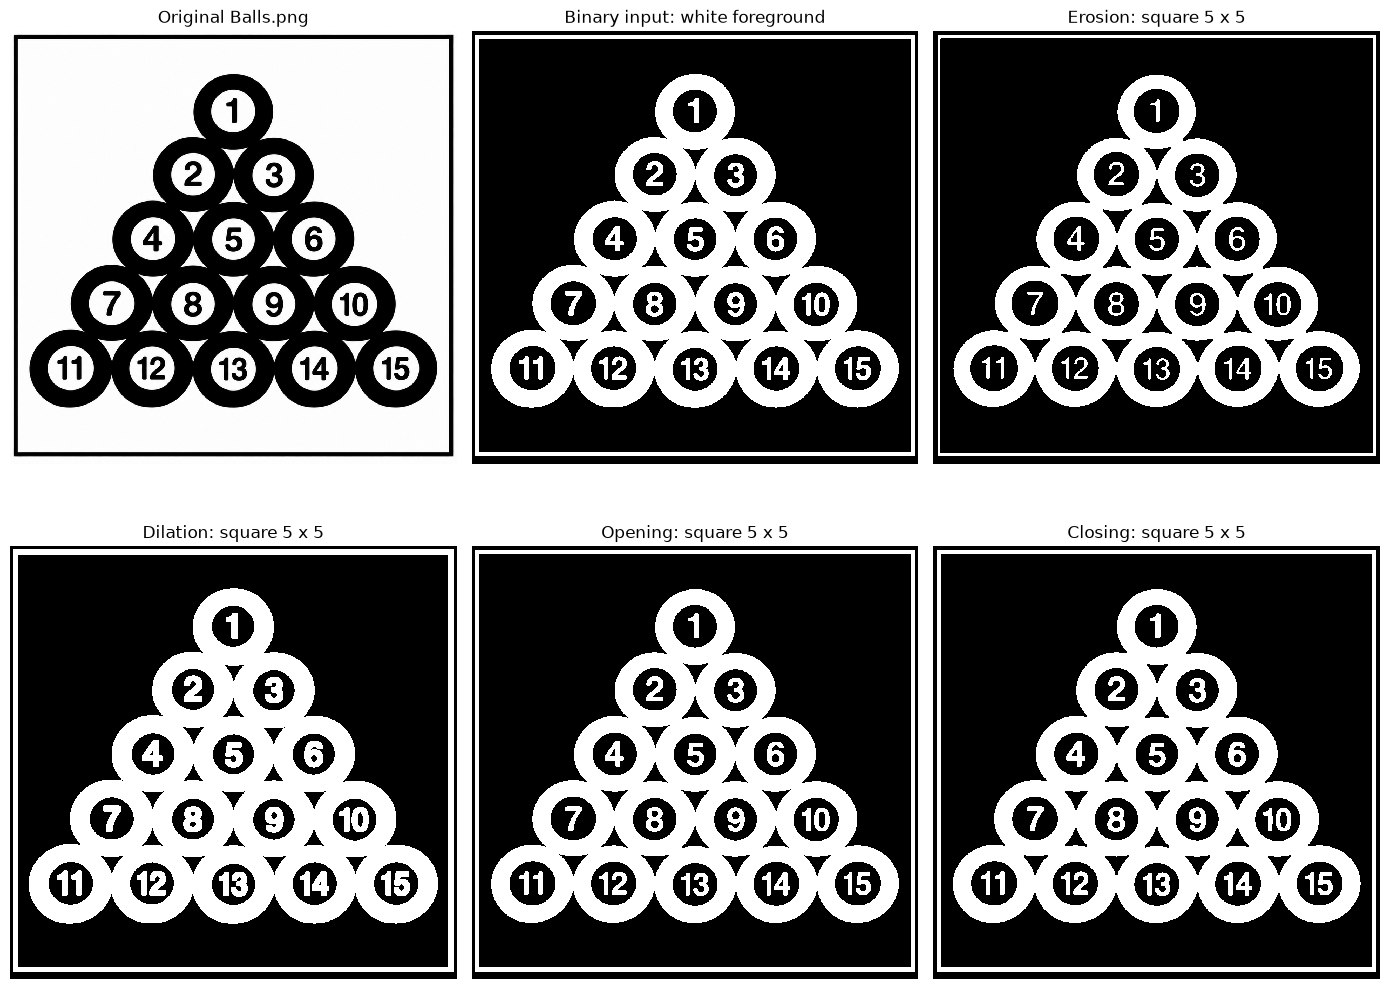

Input foreground area: 500,374 pixels
Erosion : 432,293 foreground pixels; change -68,081
Dilation: 567,126 foreground pixels; change +66,752
Opening : 500,345 foreground pixels; change -29
Closing : 501,666 foreground pixels; change +1,292


In [ ]:
balls = binary_images['Balls.png']
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
operations = {
    'Erosion': cv2.erode(balls, kernel, iterations=1),
    'Dilation': cv2.dilate(balls, kernel, iterations=1),
    'Opening': cv2.morphologyEx(balls, cv2.MORPH_OPEN, kernel),
    'Closing': cv2.morphologyEx(balls, cv2.MORPH_CLOSE, kernel)
}
show([('Original Balls.png', images['Balls.png']), ('Binary input: white foreground', balls)] +
     [(f'{name}: square 5 x 5', result) for name, result in operations.items()], size=(14, 11))
original_area = int(np.count_nonzero(balls))
print(f'Input foreground area: {original_area:,} pixels')
for name, result in operations.items():
    area = int(np.count_nonzero(result))
    print(f'{name:8s}: {area:,} foreground pixels; change {area - original_area:+,}')

## Task 2 Structuring element shapes and sizes



Shape    Size   Kernel pixels   Eroded area   Dilated area
Square    3x3             9        466395         534094
Square    5x5            25        432293         567126
Square    7x7            49        398085         599496
Cross     3x3             5        473108         527560
Cross     5x5             9        445935         554380
Cross     7x7            13        418852         580813
Ellipse   3x3             5        473108         527560
Ellipse   5x5            17        440791         559214
Ellipse   7x7            33        413345         585692


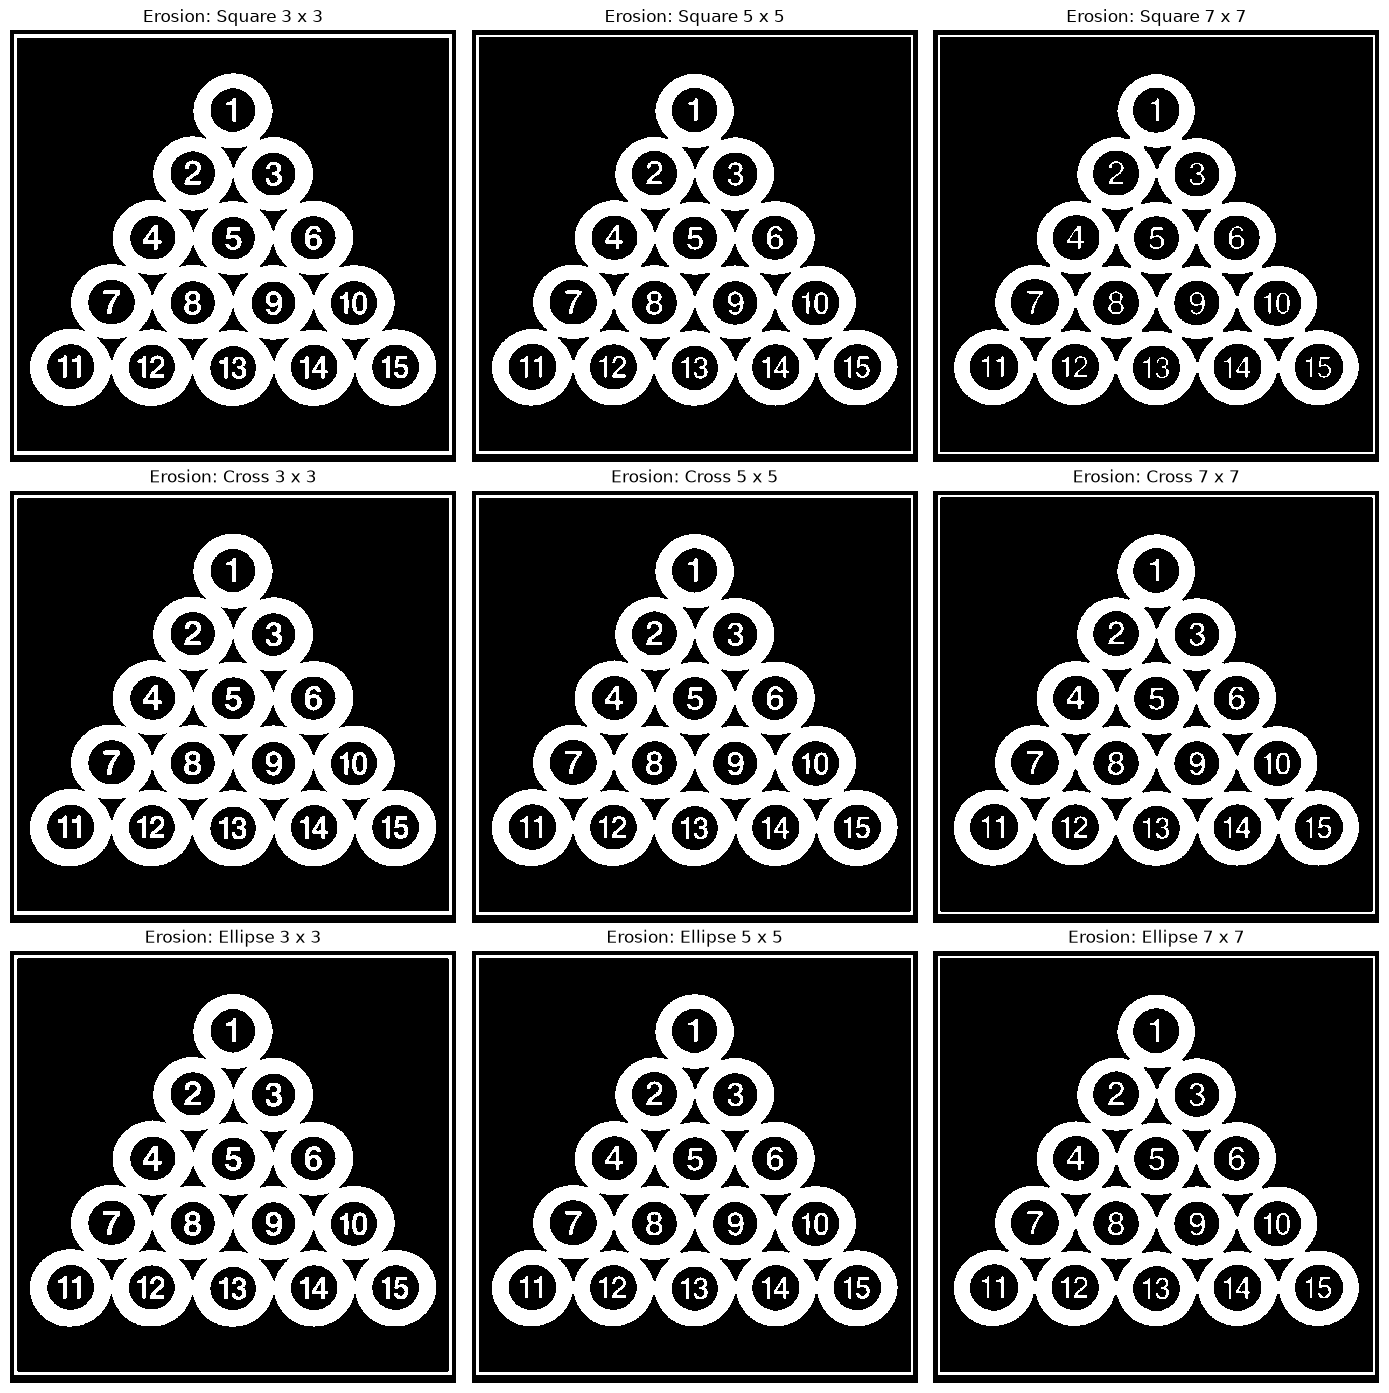

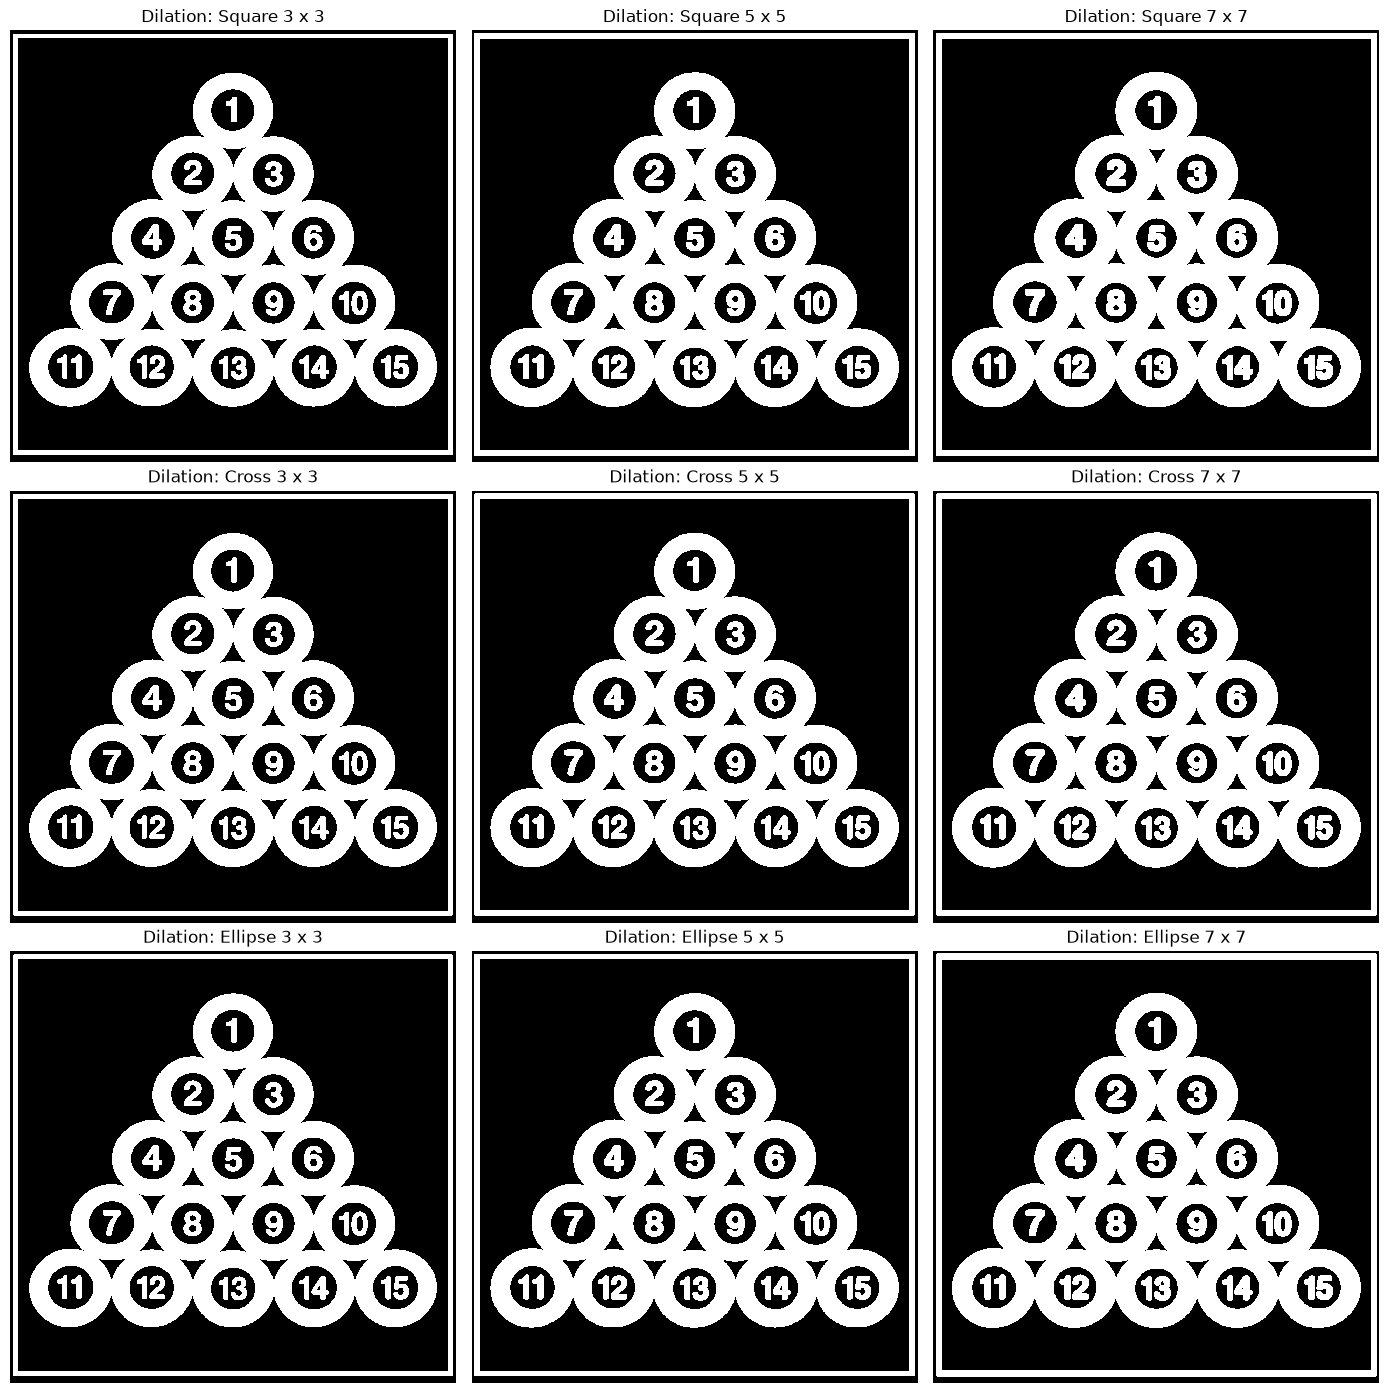

In [ ]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]
experiments = {}
print('Shape    Size   Kernel pixels   Eroded area   Dilated area')
for shape, value in shapes.items():
    for size in sizes:
        element = cv2.getStructuringElement(value, (size, size))
        erosion = cv2.erode(balls, element)
        dilation = cv2.dilate(balls, element)
        experiments[(shape, size)] = (element, erosion, dilation)
        print(f'{shape:8s} {size:2d}x{size:<2d} {np.count_nonzero(element):12d} {np.count_nonzero(erosion):13d} {np.count_nonzero(dilation):14d}')
for index, operation in [(1, 'Erosion'), (2, 'Dilation')]:
    show([(f'{operation}: {shape} {size} x {size}', experiments[(shape, size)][index])
          for shape in shapes for size in sizes], columns=3, size=(14, 14))

### Comparison and close view


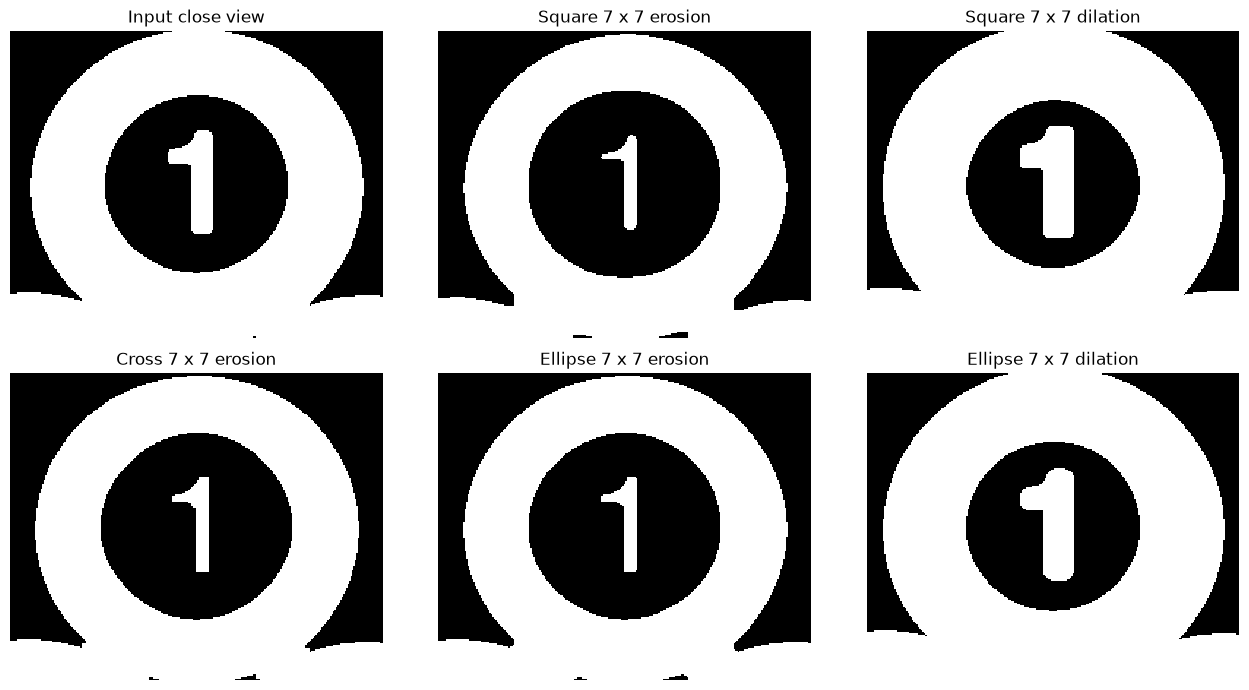

In [ ]:
height, width = balls.shape
region = (slice(int(height * 0.10), int(height * 0.27)), slice(int(width * 0.40), int(width * 0.60)))
show([
    ('Input close view', balls[region]),
    ('Square 7 x 7 erosion', experiments[('Square', 7)][1][region]),
    ('Square 7 x 7 dilation', experiments[('Square', 7)][2][region]),
    ('Cross 7 x 7 erosion', experiments[('Cross', 7)][1][region]),
    ('Ellipse 7 x 7 erosion', experiments[('Ellipse', 7)][1][region]),
    ('Ellipse 7 x 7 dilation', experiments[('Ellipse', 7)][2][region])
], columns=3, size=(13, 7))

## Reference examples Erosion and dilation


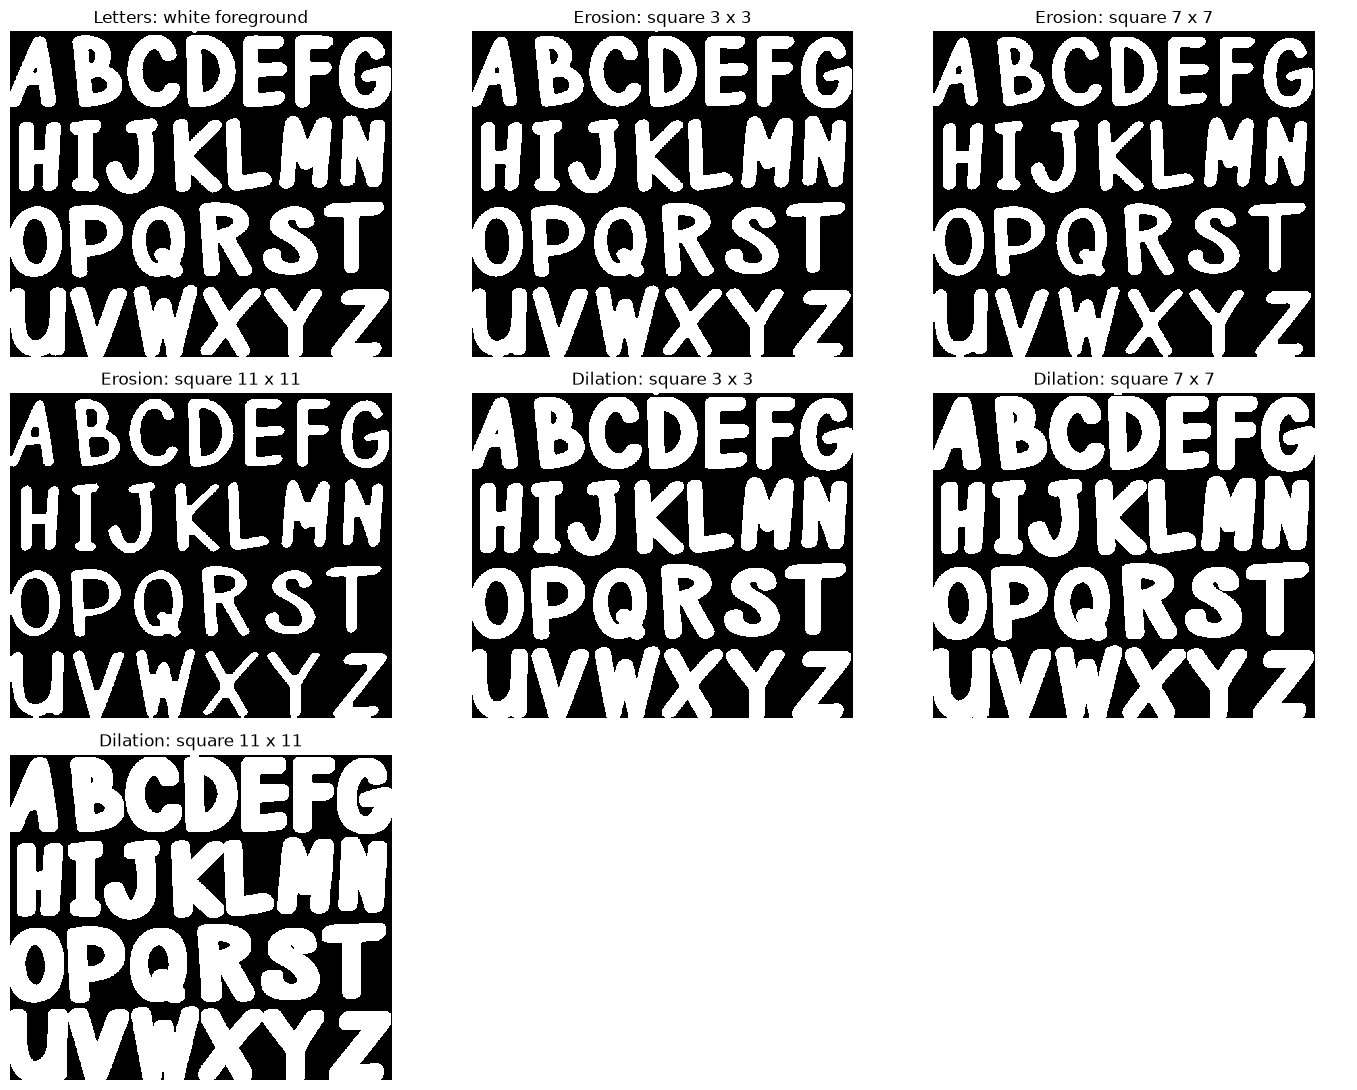

In [ ]:
letters = binary_images['Erosion2.jpg']
letter_results = [('Letters: white foreground', letters)]
for operation, function in [('Erosion', cv2.erode), ('Dilation', cv2.dilate)]:
    for size in [3, 7, 11]:
        element = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
        letter_results.append((f'{operation}: square {size} x {size}', function(letters, element)))
show(letter_results, columns=3, size=(14, 11))

## Reference examples Opening and closing


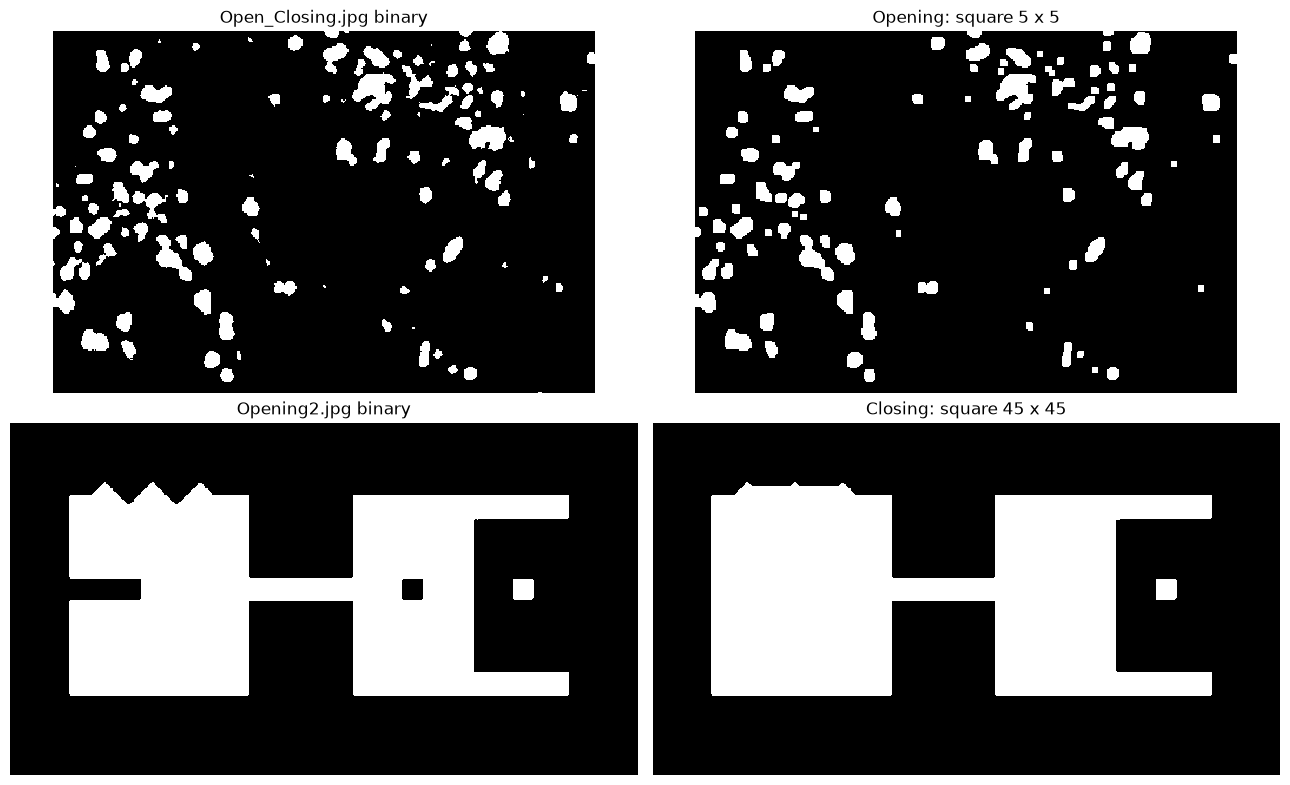

Opening removed foreground pixels: 1582
Closing added foreground pixels: 3570


In [ ]:
specks = binary_images['Open_Closing.jpg']
shape_image = binary_images['Opening2.jpg']
opening_kernel = np.ones((5, 5), dtype=np.uint8)
closing_kernel = np.ones((45, 45), dtype=np.uint8)
opened = cv2.morphologyEx(specks, cv2.MORPH_OPEN, opening_kernel)
closed = cv2.morphologyEx(shape_image, cv2.MORPH_CLOSE, closing_kernel)
show([('Open_Closing.jpg binary', specks), ('Opening: square 5 x 5', opened),
      ('Opening2.jpg binary', shape_image), ('Closing: square 45 x 45', closed)], columns=2, size=(13, 8))
print('Opening removed foreground pixels:', int(np.count_nonzero(specks) - np.count_nonzero(opened)))
print('Closing added foreground pixels:', int(np.count_nonzero(closed) - np.count_nonzero(shape_image)))

## Reference example Boundary extraction



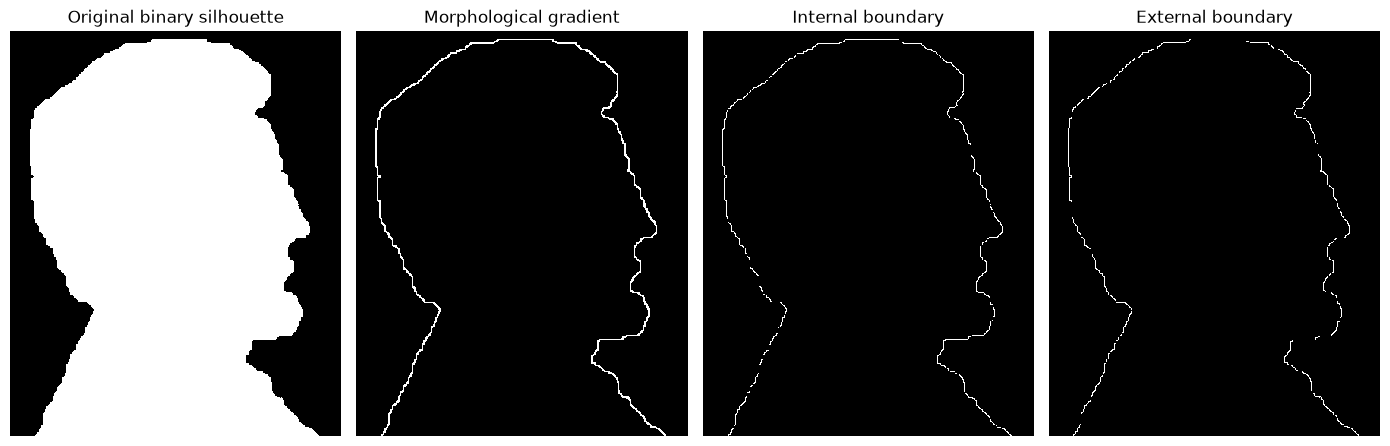

In [ ]:
silhouette = binary_images['BoundaryExtraction.jpg']
boundary_kernel = np.ones((3, 3), dtype=np.uint8)
shrunk = cv2.erode(silhouette, boundary_kernel)
expanded = cv2.dilate(silhouette, boundary_kernel)
internal = cv2.subtract(silhouette, shrunk)
external = cv2.subtract(expanded, silhouette)
gradient = cv2.morphologyEx(silhouette, cv2.MORPH_GRADIENT, boundary_kernel)
show([('Original binary silhouette', silhouette), ('Morphological gradient', gradient),
      ('Internal boundary', internal), ('External boundary', external)], columns=4, size=(14, 5))

## Verification and conclusion



In [ ]:
for image in binary_images.values():
    assert image.dtype == np.uint8 and set(np.unique(image)).issubset({0, 255})
for result in operations.values():
    assert result.shape == balls.shape and result.dtype == np.uint8
    assert set(np.unique(result)).issubset({0, 255})
assert np.all(operations['Erosion'] <= balls)
assert np.all(operations['Dilation'] >= balls)
assert np.all(operations['Opening'] <= balls)
assert np.all(operations['Closing'] >= balls)
assert np.array_equal(operations['Opening'], cv2.dilate(cv2.erode(balls, kernel), kernel))
assert np.array_equal(operations['Closing'], cv2.erode(cv2.dilate(balls, kernel), kernel))
assert np.array_equal(operations['Opening'], cv2.morphologyEx(operations['Opening'], cv2.MORPH_OPEN, kernel))
assert np.array_equal(operations['Closing'], cv2.morphologyEx(operations['Closing'], cv2.MORPH_CLOSE, kernel))
assert len(experiments) == 9
for shape in shapes:
    areas_eroded = [np.count_nonzero(experiments[(shape, size)][1]) for size in sizes]
    areas_dilated = [np.count_nonzero(experiments[(shape, size)][2]) for size in sizes]
    assert areas_eroded == sorted(areas_eroded, reverse=True)
    assert areas_dilated == sorted(areas_dilated)
for index in [0, 1, 2]:
    assert np.array_equal(experiments[('Cross', 3)][index], experiments[('Ellipse', 3)][index])
assert np.array_equal(gradient, cv2.subtract(expanded, shrunk))
assert np.array_equal(gradient, cv2.bitwise_or(internal, external))
assert not np.any(cv2.bitwise_and(internal, external))
assert np.all(internal <= silhouette)
assert np.all(external <= cv2.bitwise_not(silhouette))
print('All image, operation, kernel comparison and boundary checks passed.')
print('OpenCV:', cv2.__version__, 'NumPy:', np.__version__)

All image, operation, kernel comparison and boundary checks passed.
OpenCV: 5.0.0 NumPy: 2.5.4
